In [1]:
from plantdata import load_classes, read_manifest
from pathlib import Path
from training import run_experiment

SPLITS_DIR = Path("splits_v2")
CACHE_DIR = Path("cache_256")
CLASS_IDS, CROPS, crop_mask = load_classes(SPLITS_DIR)
manifest = read_manifest(CACHE_DIR)

run_experiment("R14", "LR sweep: AdamW lr 1e-5 (bracket AdamW optimum)", manifest, CACHE_DIR, CLASS_IDS, CROPS,
               crop_mask, depth=18, freeze="none", augment=True, optimiser="adamw", lr=1e-5, weight_decay=0.01,
               batch_size=64, epochs=15, patience=5, seed=42)

R14: LR sweep: AdamW lr 1e-5 (bracket AdamW optimum) | 11,186,772 trainable weights
  epoch  1 | lr 1.00e-05 | train loss 0.729 acc 0.763 | val_lab F1-16 0.802 | val_wild F1-16 0.407 * | 122 s
  epoch  2 | lr 9.89e-06 | train loss 0.277 acc 0.926 | val_lab F1-16 0.915 | val_wild F1-16 0.454 * | 34 s
  epoch  3 | lr 9.57e-06 | train loss 0.162 acc 0.957 | val_lab F1-16 0.939 | val_wild F1-16 0.465 * | 41 s
  epoch  4 | lr 9.05e-06 | train loss 0.118 acc 0.968 | val_lab F1-16 0.948 | val_wild F1-16 0.469 * | 34 s
  epoch  5 | lr 8.35e-06 | train loss 0.094 acc 0.974 | val_lab F1-16 0.959 | val_wild F1-16 0.466 | 35 s
  epoch  6 | lr 7.50e-06 | train loss 0.079 acc 0.978 | val_lab F1-16 0.964 | val_wild F1-16 0.465 | 35 s
  epoch  7 | lr 6.55e-06 | train loss 0.068 acc 0.982 | val_lab F1-16 0.965 | val_wild F1-16 0.461 | 35 s
  epoch  8 | lr 5.52e-06 | train loss 0.064 acc 0.981 | val_lab F1-16 0.969 | val_wild F1-16 0.462 | 35 s
  epoch  9 | lr 4.48e-06 | train loss 0.058 acc 0.984 | val

({'run_id': 'R14',
  'date': '2026-10-26 11:34',
  'note': 'LR sweep: AdamW lr 1e-5 (bracket AdamW optimum)',
  'depth': 18,
  'pretrained': True,
  'freeze': 'none',
  'augment': True,
  'optimiser': 'adamw',
  'lr': 1e-05,
  'weight_decay': 0.01,
  'batch_size': 64,
  'epochs': 15,
  'patience': 5,
  'class_weights': 'none',
  'dropout': 0.2,
  'seed': 42,
  'num_workers': 8,
  'trainable_weights': 11186772,
  'epochs_run': 9,
  'best_epoch': 4,
  'val_lab_f1_16': 0.948329897993272,
  'val_wild_f1_16': 0.4694137346448182,
  'val_wild_f1_20': 0.4894391386666358,
  'val_wild_late_blight_recall': 0.7038118131868132,
  'val_wild_accuracy': 0.5128834355828221,
  'train_minutes': 6.792410504999377,
  'ms_per_image': 0.4268565912577218},
    epoch        lr  train_loss  train_acc  val_lab_macro_f1_16_disease  \
 0      1  0.000010    0.728899   0.762695                     0.801999   
 1      2  0.000010    0.277209   0.925673                     0.914656   
 2      3  0.000010    0.161949 

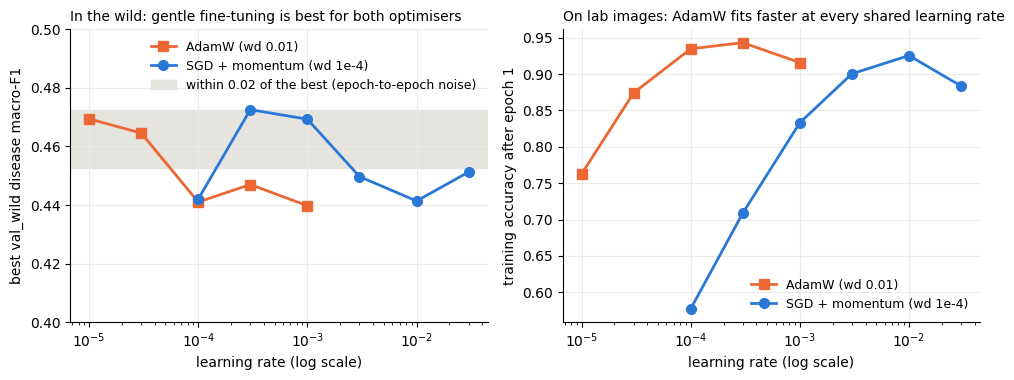

,run_id,optimiser,lr,val_wild_best,train_acc_epoch1
10,R14,adamw,0.0000,0.4694,0.7627
9,R13,adamw,0.0000,0.4646,0.8742
4,R08,adamw,0.0001,0.4410,0.9347
5,R09,adamw,0.0003,0.4470,0.9433
6,R10,adamw,0.0010,0.4397,0.9159
8,R12,sgd,0.0001,0.4420,0.5774
7,R11,sgd,0.0003,0.4726,0.7089
1,R05,sgd,0.0010,0.4693,0.8332
2,R06,sgd,0.0030,0.4497,0.9004
0,R04,sgd,0.0100,0.4414,0.9256


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import json
SWEEP_IDS = ["R04", "R05", "R06", "R07", "R08", "R09", "R10", "R11", "R12", "R13", "R14"]   # all: R18, full fine-tune, aug, bs 64, seed 42

rows = []
for run_id in SWEEP_IDS:
    cfg = json.loads((Path("results/runs") / run_id / "config.json").read_text())
    h = pd.read_csv(Path("results/runs") / run_id / "history.csv")
    rows.append({"run_id": run_id, "optimiser": cfg["optimiser"], "lr": cfg["lr"],
                 "val_wild_best": h["val_wild_macro_f1_16_disease"].max(),
                 "train_acc_epoch1": h["train_acc"].iloc[0]})
sweep = pd.DataFrame(rows).sort_values(["optimiser", "lr"])

STYLE = {"sgd": ("#2a78d6", "o", "SGD + momentum (wd 1e-4)"), "adamw": ("#eb6834", "s", "AdamW (wd 0.01)")}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.9))
for opt, g in sweep.groupby("optimiser"):
    colour, marker, label = STYLE[opt]
    ax1.plot(g["lr"], g["val_wild_best"], color=colour, marker=marker, ms=7, lw=2, label=label)
    ax2.plot(g["lr"], g["train_acc_epoch1"], color=colour, marker=marker, ms=7, lw=2, label=label)
best = sweep.loc[sweep["val_wild_best"].idxmax()]
ax1.axhspan(best["val_wild_best"] - 0.02, best["val_wild_best"], color="#e5e4df", zorder=0,
            label="within 0.02 of the best (epoch-to-epoch noise)")
ax1.set_ylim(0.40, 0.50)
ax1.set_ylabel("best val_wild disease macro-F1")
ax1.set_title("In the wild: gentle fine-tuning is best for both optimisers", fontsize=10, loc="left")
ax2.set_ylabel("training accuracy after epoch 1")
ax2.set_title("On lab images: AdamW fits faster at every shared learning rate", fontsize=10, loc="left")
for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_xlabel("learning rate (log scale)")
    ax.grid(color="#ebeae5", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="upper right" if ax is ax1 else "lower right")
fig.tight_layout()
fig.savefig("figures/q3b_lr_optimiser.png", dpi=200)
plt.show()
sweep.round(4)